In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# FILE NO 1

In [12]:
df=pd.read_csv("hotel_booking.csv")

In [13]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [14]:
df["agent"]=df["agent"].fillna(0)
df["company"]=df["company"].fillna(0)
df["children"]=df["children"].fillna(0)
df["country"]=df["country"].fillna("unknown")

In [15]:
df.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [24]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103886,0.007949,0.031912,0.087118,0.137097,0.221124,74.828319,10.775157,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398555,0.097436,0.175767,0.844336,1.497437,0.652306,107.141953,53.943884,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,0.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,152.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [41]:
df.describe(include=["object", "str"])

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date,name,email,phone-number,credit_card
count,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,178,8,5,10,12,3,4,3,926,81503,115889,119390,9000
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21,Michael Johnson,Michael.C@gmail.com,669-792-1661,************3627
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461,48,6,1,28


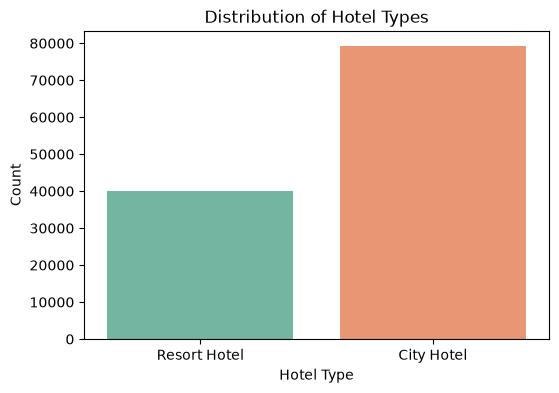

In [27]:
plt.figure(figsize=(6, 4))
sns.countplot(x="hotel", data=df, hue="hotel", palette="Set2", legend=False)
plt.title("Distribution of Hotel Types")
plt.xlabel("Hotel Type")
plt.ylabel("Count")
plt.show()

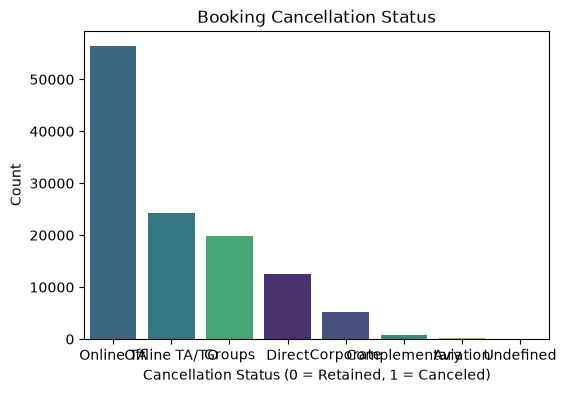


Cancellation Percentage:
 is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


In [31]:
plt.figure(figsize=(6, 4))
sns.countplot(
    x="market_segment",
    data=df,
    hue="market_segment",
    order=df["market_segment"].value_counts().index,
    palette="viridis",
    legend=False,
)
plt.title("Booking Cancellation Status")
plt.xlabel("Cancellation Status (0 = Retained, 1 = Canceled)")
plt.ylabel("Count")
plt.show()

canceled_perc = df["is_canceled"].value_counts(normalize=True) * 100
print("\nCancellation Percentage:\n", canceled_perc)

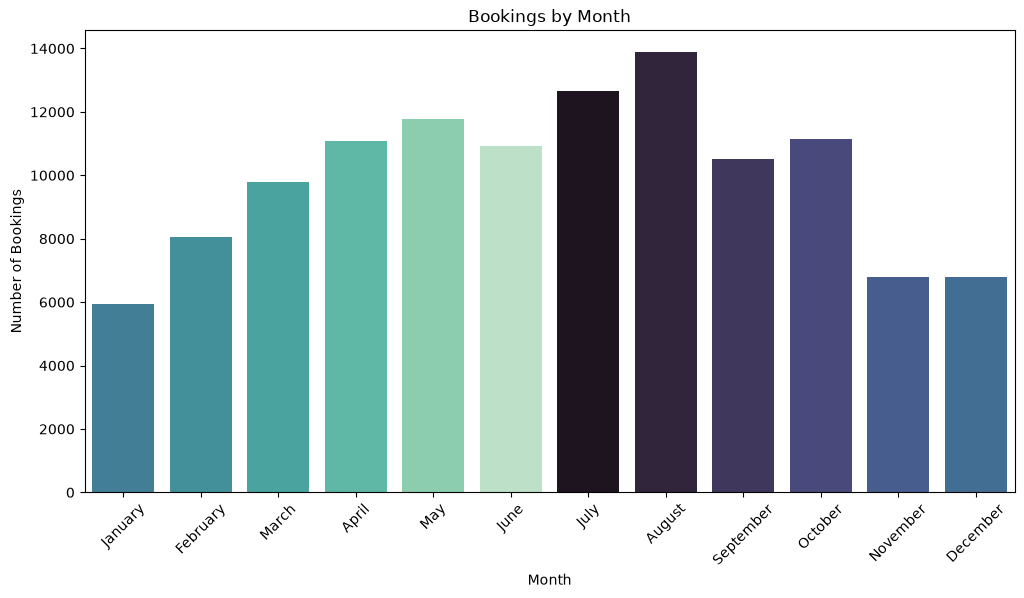

In [37]:
months_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
plt.figure(figsize=(12, 6))
sns.countplot(x="arrival_date_month",hue="arrival_date_month", data=df, order=months_order, palette="mako")
plt.title("Bookings by Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

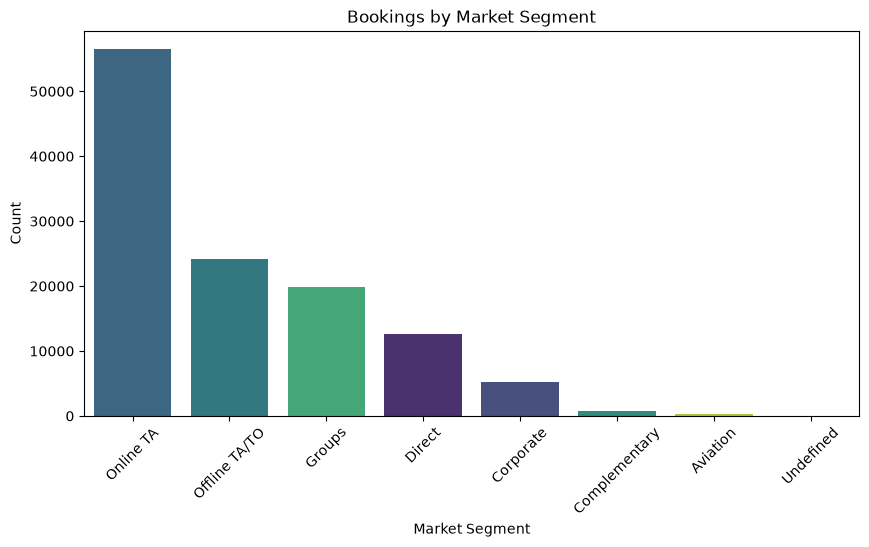

In [38]:
plt.figure(figsize=(10, 5))
sns.countplot(
    x="market_segment",
    hue="market_segment",
    data=df,
    order=df["market_segment"].value_counts().index,
    palette="viridis",
)
plt.title("Bookings by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

Text(0.5, 1.0, 'Correlation Heatmap')

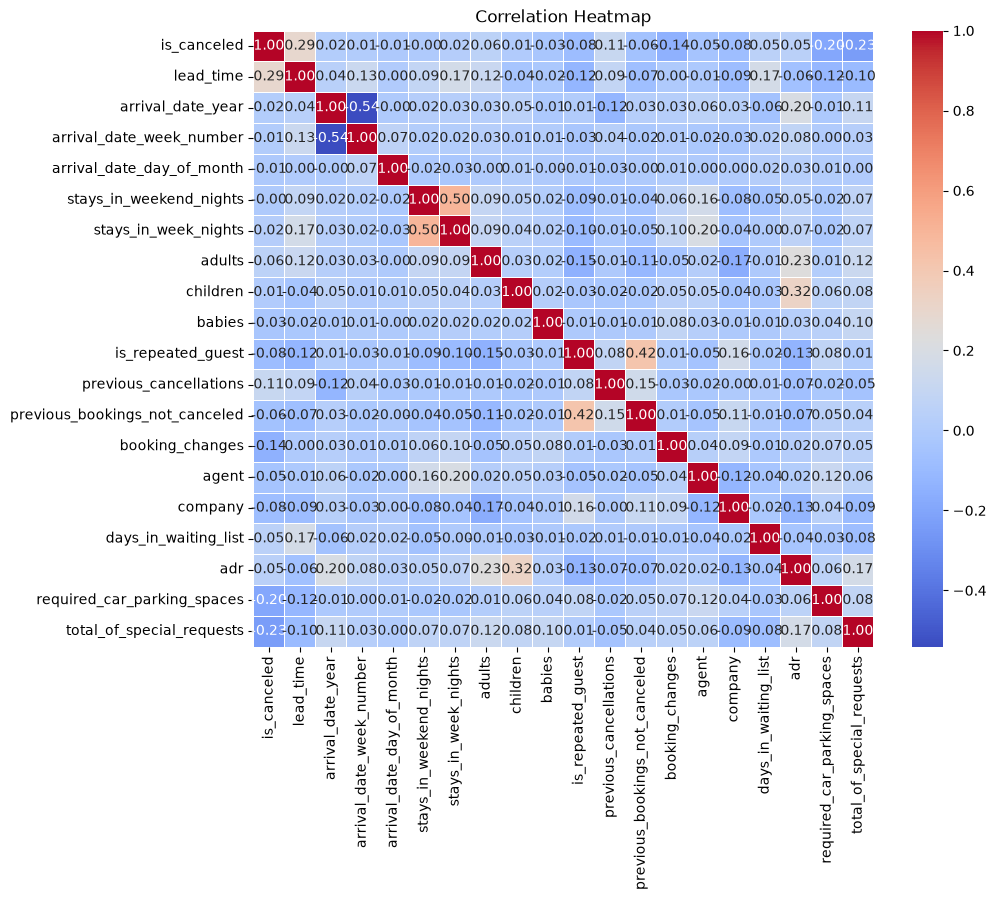

In [39]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
correlation = numeric_df.corr()
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5
)
plt.title("Correlation Heatmap")

# FILE NO 2

In [2]:
df2=pd.read_csv("adult.csv")

In [3]:
df2.shape

(48842, 15)

In [4]:
df2.duplicated().sum()

np.int64(52)

In [5]:
df2=df2.drop_duplicates()

In [6]:
df2.duplicated().sum()

np.int64(0)

In [7]:
df2.isna().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [9]:
df2=df2.drop("fnlwgt",axis=1)

In [10]:
df2.head()

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [14]:
df2.dtypes

age                int64
workclass            str
education            str
educational-num    int64
marital-status       str
occupation           str
relationship         str
race                 str
gender               str
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country       str
income               str
dtype: object

# FILE NO 3

In [2]:
df3=pd.read_csv("loan-train.csv")

In [3]:
df3.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df3.duplicated().sum()

np.int64(0)

In [5]:
df3.Loan_ID.value_counts().head(10)

Loan_ID
LP006706    3
LP003002    2
LP003029    2
LP003103    2
LP003139    2
LP003339    2
LP003435    2
LP003461    2
LP003618    2
LP003624    2
Name: count, dtype: int64

In [6]:
df3=df3.drop_duplicates(subset=['Loan_ID'], keep='first')

In [7]:
df3.Loan_ID.value_counts().head(10)

Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
LP001011    1
LP001013    1
LP001014    1
LP001018    1
LP001020    1
Name: count, dtype: int64

In [8]:
df3.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [16]:
df3.columns=df3.columns.str.strip()
for col in ["Gender","Married","Self_Employed","Dependents"]:
    df3[col]=df3[col].fillna(df3[col].mode()[0])

In [17]:
df3.isna().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [21]:
df3["LoanAmount"].describe()

count    1516.000000
mean      216.177441
std       132.525873
min         9.000000
25%       111.000000
50%       176.000000
75%       320.000000
max       700.000000
Name: LoanAmount, dtype: float64

In [22]:
for col in ["LoanAmount","Loan_Amount_Term","Credit_History"]:
    df3[col]=df3[col].fillna(df3[col].median())

In [23]:
df3.isna().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64